# ISIC 2020 — Lightweight CNN v1 and v2

From-scratch CNN training, patient-level validation and automatic internal held-out test evaluation.

**Storage:** Google Drive mounting is disabled because authentication failed. The dataset is already downloaded to `/content/images_uint8_new.npy`. Best checkpoints are written to `/content/checkpoints` (temporary Colab storage) and browser downloads are triggered on every validation AUPRC improvement and at the end of each model. Allow multiple downloads and verify the **latest** `.pth` for each model on your computer. An end-of-run results ZIP is also downloaded. **Do not restart the runtime before securing files.**

**Shared preprocessing and splitting:** team members Monirul Islam and Aniket Bhanderi.

CNN v1/v2 architecture and experiments: **bold text** Muhammad Mubinur Rahman.


In [1]:
import requests
import os

url = "https://mailuc-my.sharepoint.com/:u:/g/personal/rahmamn_mail_uc_edu/IQAIS2spTrqZQo5KpiNS3xt_AT6P3JINpBXF6LWyemUHJSs?e=SOaBPK"

download_url = url + "&download=1"
destination = "/content/images_uint8_new.npy"

with requests.get(download_url, stream=True, timeout=120) as r:
    r.raise_for_status()
    print("Content type:", r.headers.get("Content-Type"))

    with open(destination, "wb") as f:
        for chunk in r.iter_content(chunk_size=8 * 1024 * 1024):
            if chunk:
                f.write(chunk)

print("Downloaded size:", os.path.getsize(destination), "bytes")

Content type: application/octet-stream
Downloaded size: 6429278336 bytes


In [4]:
import numpy as np
import os

path = "/content/images_uint8_new.npy"

print("File size:", os.path.getsize(path))

data = np.load(path, mmap_mode="r")
print("Shape:", data.shape)
print("Data type:", data.dtype)

File size: 6429278336
Shape: (32701, 256, 256, 3)
Data type: uint8


## Setup checklist

1. Select GPU in Colab. Keep this runtime connected; the dataset is already at `/content/images_uint8_new.npy`.
2. Ensure `/content/isic/metadata.csv` and `/content/isic/isic_utils.py` exist.
3. Run setup and **test download** cells. Confirm `download_test.txt` reaches your computer.
4. **Allow multiple automatic downloads** in your browser before training. Every improved checkpoint triggers a download; the final best checkpoint is downloaded again after each model.
5. Run cells in order. The held-out internal test evaluation runs automatically after training and validation; it is not used for model selection.
6. Confirm both best `.pth` files and final results ZIP are on your computer before ending Colab.


In [8]:
from pathlib import Path
import os, sys, json, shutil, random
import numpy as np
import pandas as pd
import torch
from google.colab import files

# Google Drive mount is intentionally NOT required.
INPUT_DIR = Path('/content/isic')
CACHE_PATH = Path('/content/images_uint8_new.npy')
META_PATH = INPUT_DIR / 'metadata.csv'
UTILS_DIR = INPUT_DIR

RUN_DIR = Path('/content/isic_lightweight_cnn_retrain')
CHECKPOINT_DIR = Path('/content/checkpoints')
RESULTS_DIR = RUN_DIR / 'results'
GITHUB_DIR = RUN_DIR / 'github_upload'
for folder in (CHECKPOINT_DIR, RESULTS_DIR, GITHUB_DIR):
    folder.mkdir(parents=True, exist_ok=True)

CNN1_CKPT = CHECKPOINT_DIR / 'best_lightweight_cnn.pth'
CNN2_CKPT = CHECKPOINT_DIR / 'best_lightweight_cnn_v2.pth'

for p in (META_PATH, CACHE_PATH, UTILS_DIR / 'isic_utils.py'):
    if not p.is_file():
        raise FileNotFoundError(f'Missing input: {p}. Fix the paths above before training.')

print('Checkpoint directory (TEMPORARY):', CHECKPOINT_DIR)
print('Inputs verified. Do not restart Colab.')


Checkpoint directory (TEMPORARY): /content/checkpoints
Inputs verified. Do not restart Colab.


In [9]:
# SAFETY CHECK: verify browser downloads BEFORE beginning lengthy training.
# When prompted by Chrome, ALLOW multiple automatic downloads from Colab.
from google.colab import files
from pathlib import Path

CHECKPOINT_DIR = Path('/content/checkpoints')
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
probe = CHECKPOINT_DIR / 'download_test.txt'
probe.write_text('Colab checkpoint download test')
files.download(str(probe))
print('Confirm download_test.txt is on your computer BEFORE running training.')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Confirm download_test.txt is on your computer BEFORE running training.


## 1. Imports, paths, and dataset

Uses the shared `CachedISIC` and `build_transforms` utilities, matching the team preprocessing. The metadata is split by `split_patient`, not by image-level random assignment.

In [10]:
import sys
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

sys.path.insert(0, str(UTILS_DIR))
import isic_utils as U
meta = pd.read_csv(META_PATH)
required = {'split_patient', 'cache_index', 'target'}
if not required.issubset(meta.columns):
    raise ValueError(f'Metadata missing columns: {required - set(meta.columns)}')
print(meta['split_patient'].value_counts())
print('Labeled target counts by split:')
print(meta.groupby('split_patient')['target'].agg(['count','sum']))


split_patient
train    23364
test      4674
val       4663
Name: count, dtype: int64
Labeled target counts by split:
               count  sum
split_patient            
test            4674   82
train          23364  414
val             4663   85


In [11]:
import sys
sys.path.insert(0, "/content/isic")

import isic_utils as U
from torch.utils.data import DataLoader

# Configuration
CACHE_PATH = str(CACHE_PATH)  # verified in Drive setup cell
IMG_SIZE = 224
BATCH_SIZE = 64

# Patient-level training and validation splits
train_meta = meta[meta["split_patient"] == "train"]
val_meta = meta[meta["split_patient"] == "val"]

# Datasets
train_dataset = U.CachedISIC(
    CACHE_PATH,
    train_meta["cache_index"].to_numpy(),
    train_meta["target"].to_numpy(),
    U.build_transforms(IMG_SIZE, train=True)
)

val_dataset = U.CachedISIC(
    CACHE_PATH,
    val_meta["cache_index"].to_numpy(),
    val_meta["target"].to_numpy(),
    U.build_transforms(IMG_SIZE, train=False)
)

# DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

# Verify one batch
X, y = next(iter(train_loader))

print("Image batch shape:", X.shape)
print("Label batch shape:", y.shape)

Training images: 23364
Validation images: 4663
Image batch shape: torch.Size([64, 3, 224, 224])
Label batch shape: torch.Size([64])


## 2. CNN v1 — 2 convolutional layers

Original baseline: 19,457 trainable parameters. AdamW, square-root positive class weighting, 2-epoch warmup and cosine decay, 20-epoch maximum, and patience 5. Best checkpoint selected by validation AUPRC.

In [27]:
import torch
import torch.nn as nn

class LightweightCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x).squeeze(1)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = LightweightCNN().to(device)

print("Device:", device)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

with torch.no_grad():
    output = model(X.to(device))

print("Output shape:", output.shape)


Device: cuda
Trainable parameters: 19457
Output shape: torch.Size([64])


In [28]:
import numpy as np
import torch.nn as nn
import torch.optim as optim

# Calculate class imbalance from training data only
positive = (train_meta["target"] == 1).sum()
negative = (train_meta["target"] == 0).sum()

pos_weight = np.sqrt(negative / positive)

print("Malignant:", positive)
print("Benign:", negative)
print("Positive weight:", pos_weight)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [pos_weight], dtype=torch.float32, device=device
    )
)

optimizer = optim.AdamW(
    model.parameters(),
    lr=2e-4,
    weight_decay=1e-4
)

Malignant: 414
Benign: 22950
Positive weight: 7.445453821540743


In [29]:
import math

EPOCHS = 20
WARMUP_EPOCHS = 2
PATIENCE = 5

steps_per_epoch = len(train_loader)
total_steps = EPOCHS * steps_per_epoch
warmup_steps = WARMUP_EPOCHS * steps_per_epoch

def lr_lambda(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps

    progress = (step - warmup_steps) / max(
        1, total_steps - warmup_steps
    )

    return 0.5 * (1 + math.cos(math.pi * progress))

scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lr_lambda
)

best_auprc = -1.0
patience_counter = 0

In [30]:
from sklearn.metrics import average_precision_score, roc_auc_score
from tqdm.auto import tqdm
import numpy as np
import torch
import copy

history = {
    "train_loss": [],
    "val_loss": [],
    "val_auprc": [],
    "val_auroc": []
}

best_state = None

for epoch in range(EPOCHS):

    # ---------- TRAINING ----------
    model.train()
    running_loss = 0.0

    for images_batch, labels_batch in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    ):
        images_batch = images_batch.to(device, non_blocking=True)
        labels_batch = labels_batch.to(device, non_blocking=True)

        optimizer.zero_grad()

        logits = model(images_batch)
        loss = criterion(logits, labels_batch)

        loss.backward()
        optimizer.step()
        scheduler.step()

        running_loss += loss.item() * labels_batch.size(0)

    train_loss = running_loss / len(train_dataset)

    # ---------- VALIDATION ----------
    model.eval()
    val_running_loss = 0.0
    all_probs = []
    all_labels = []

    with torch.no_grad():
        for images_batch, labels_batch in val_loader:
            images_batch = images_batch.to(device, non_blocking=True)
            labels_batch = labels_batch.to(device, non_blocking=True)

            logits = model(images_batch)
            loss = criterion(logits, labels_batch)

            probs = torch.sigmoid(logits)

            val_running_loss += loss.item() * labels_batch.size(0)

            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(labels_batch.cpu().numpy())

    val_loss = val_running_loss / len(val_dataset)

    val_auprc = average_precision_score(all_labels, all_probs)
    val_auroc = roc_auc_score(all_labels, all_probs)

    # ---------- SAVE HISTORY ----------
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_auprc"].append(val_auprc)
    history["val_auroc"].append(val_auroc)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"AUPRC: {val_auprc:.4f} | "
        f"AUROC: {val_auroc:.4f}"
    )

    # ---------- EARLY STOPPING ----------
    if val_auprc > best_auprc:
        best_auprc = val_auprc
        patience_counter = 0

        best_state = copy.deepcopy(model.state_dict())

        torch.save(
            best_state,
            CNN1_CKPT
        )

        print(f"Best CNN v1 checkpoint saved locally: {CNN1_CKPT}")
        try:
            files.download(str(CNN1_CKPT))
            print('CHECK YOUR COMPUTER: best_lightweight_cnn.pth (latest best)')
        except Exception as exc:
            print('WARNING: automatic download failed:', exc)
            print('Download manually from /content/checkpoints before disconnecting.')

    else:
        patience_counter += 1

        if patience_counter >= PATIENCE:
            print("Early stopping triggered.")
            break

# Restore best validation checkpoint
if best_state is not None:
    model.load_state_dict(best_state)

print(f"\nBest Validation AUPRC: {best_auprc:.4f}")
assert CNN1_CKPT.is_file(), "Checkpoint not saved locally!"

# Final safety download of CNN v1 best checkpoint (verify in Downloads folder).
try:
    files.download(str(CNN1_CKPT))
except Exception as exc:
    print('WARNING: final checkpoint download failed:', exc)


Epoch 1/20:   0%|          | 0/366 [00:00<?, ?it/s]

Epoch 1/20 | Train Loss: 0.4977 | Val Loss: 0.3675 | AUPRC: 0.0416 | AUROC: 0.7464
Best CNN v1 checkpoint saved locally: /content/checkpoints/best_lightweight_cnn.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

CHECK YOUR COMPUTER: best_lightweight_cnn.pth (latest best)


Epoch 2/20:   0%|          | 0/366 [00:00<?, ?it/s]

... (62 outputs left out)

Epoch 20/20:   0%|          | 0/366 [00:00<?, ?it/s]

Epoch 20/20 | Train Loss: 0.3641 | Val Loss: 0.3673 | AUPRC: 0.0516 | AUROC: 0.7487

Best Validation AUPRC: 0.0520


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### CNN v1 validation evaluation and exports

F1 threshold is selected on validation data; these threshold-dependent validation metrics are optimistic and should not be interpreted as independent test results.

In [31]:
import torch
import numpy as np
import pandas as pd
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    precision_recall_curve,
    roc_curve
)

model.load_state_dict(
    torch.load(
        CNN1_CKPT,
        map_location=device,
        weights_only=True
    )
)

model.eval()

val_probs = []
val_labels = []

with torch.no_grad():
    for images_batch, labels_batch in val_loader:
        images_batch = images_batch.to(device)

        logits = model(images_batch)
        probs = torch.sigmoid(logits)

        val_probs.extend(probs.cpu().numpy())
        val_labels.extend(labels_batch.numpy())

val_probs = np.array(val_probs)
val_labels = np.array(val_labels).astype(int)

print("Validation samples:", len(val_labels))
print("Malignant samples:", val_labels.sum())
print("AUPRC:", average_precision_score(val_labels, val_probs))
print("AUROC:", roc_auc_score(val_labels, val_probs))

Validation samples: 4663
Malignant samples: 85
AUPRC: 0.05201462337769865
AUROC: 0.7491866471359185


In [32]:
precision_curve, recall_curve, thresholds = precision_recall_curve(
    val_labels, val_probs
)

f1_values = (
    2 * precision_curve[:-1] * recall_curve[:-1]
    / (precision_curve[:-1] + recall_curve[:-1] + 1e-12)
)

best_idx = np.argmax(f1_values)
best_threshold = float(thresholds[best_idx])

val_preds = (val_probs >= best_threshold).astype(int)

metrics = {
    "AUPRC": average_precision_score(val_labels, val_probs),
    "AUROC": roc_auc_score(val_labels, val_probs),
    "Precision": precision_score(val_labels, val_preds, zero_division=0),
    "Recall": recall_score(val_labels, val_preds, zero_division=0),
    "F1": f1_score(val_labels, val_preds, zero_division=0),
    "Balanced Accuracy": balanced_accuracy_score(val_labels, val_preds),
    "Threshold": best_threshold
}

tn, fp, fn, tp = confusion_matrix(
    val_labels, val_preds, labels=[0, 1]
).ravel()

metrics.update({
    "TP": int(tp),
    "FP": int(fp),
    "FN": int(fn),
    "TN": int(tn)
})

print(pd.Series(metrics).round(4))
from sklearn.metrics import matthews_corrcoef, accuracy_score
metrics.update({
    "Accuracy": accuracy_score(val_labels, val_preds),
    "Specificity": float(tn / (tn + fp)) if (tn + fp) else 0.0,
    "MCC": matthews_corrcoef(val_labels, val_preds)
})
print('CNN v1 validation metrics (including accuracy, specificity, MCC):')
print(pd.Series(metrics).round(4))


AUPRC                   0.0520
AUROC                   0.7492
Precision               0.0732
Recall                  0.2471
F1                      0.1129
Balanced Accuracy       0.5945
Threshold               0.2226
TP                     21.0000
FP                    266.0000
FN                     64.0000
TN                   4312.0000
dtype: float64
CNN v1 validation metrics (including accuracy, specificity, MCC):
AUPRC                   0.0520
AUROC                   0.7492
Precision               0.0732
Recall                  0.2471
F1                      0.1129
Balanced Accuracy       0.5945
Threshold               0.2226
TP                     21.0000
FP                    266.0000
FN                     64.0000
TN                   4312.0000
Accuracy                0.9292
Specificity             0.9419
MCC                     0.1052
dtype: float64


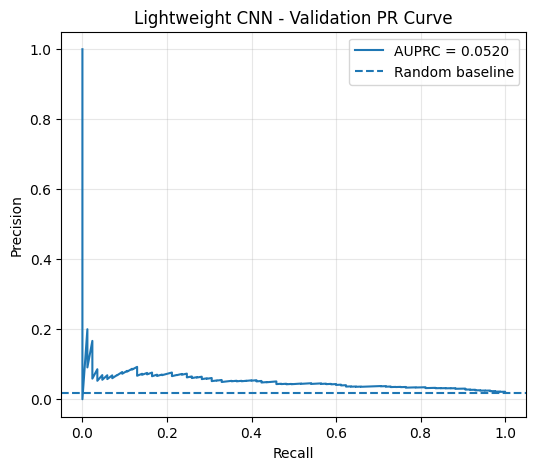

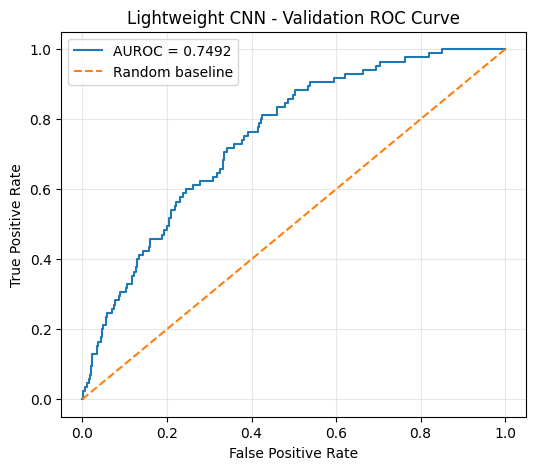

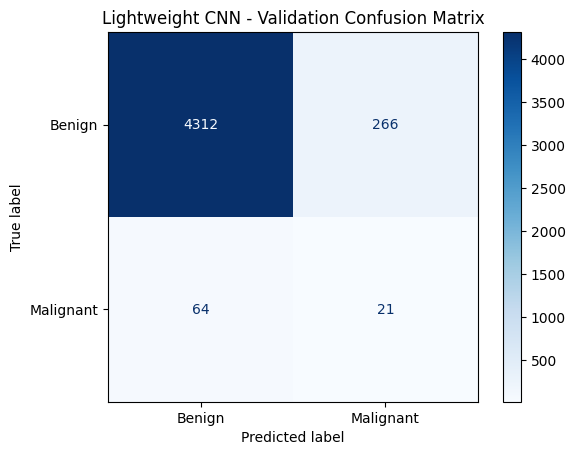

In [33]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from pathlib import Path

SAVE_DIR = RESULTS_DIR / "cnn_v1"
SAVE_DIR.mkdir(exist_ok=True)

# Precision-Recall curve
plt.figure(figsize=(6, 5))
plt.plot(recall_curve, precision_curve,
         label=f"AUPRC = {metrics['AUPRC']:.4f}")
plt.axhline(val_labels.mean(), linestyle="--",
            label="Random baseline")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Lightweight CNN - Validation PR Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(SAVE_DIR / "pr_curve.png", dpi=300, bbox_inches="tight")
plt.show()

# ROC curve
fpr, tpr, _ = roc_curve(val_labels, val_probs)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUROC = {metrics['AUROC']:.4f}")
plt.plot([0, 1], [0, 1], "--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Lightweight CNN - Validation ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(SAVE_DIR / "roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

# Confusion matrix
cm = confusion_matrix(val_labels, val_preds, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Lightweight CNN - Validation Confusion Matrix")
plt.savefig(SAVE_DIR / "confusion_matrix.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [34]:
import json
import shutil

# Metrics
with open(SAVE_DIR / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

# Predictions, in the same order as val_meta
predictions_df = val_meta[
    ["cache_index", "target"]
].reset_index(drop=True).copy()

predictions_df["probability_malignant"] = val_probs
predictions_df["predicted_label"] = val_preds

predictions_df.to_csv(
    SAVE_DIR / "validation_predictions.csv",
    index=False
)

# Training history
pd.DataFrame(history).to_csv(
    SAVE_DIR / "training_history.csv",
    index=False
)

# Best model
shutil.copy2(
    CNN1_CKPT,
    SAVE_DIR / "best_lightweight_cnn.pth"
)

# Bundle everything
shutil.make_archive(
    str(RESULTS_DIR / "cnn_v1"),
    "zip",
    SAVE_DIR
)

print("Saved results in Drive:", SAVE_DIR)

Saved results in Drive: /content/isic_lightweight_cnn_retrain/results/cnn_v1


## 3. CNN v2 — 3 convolutional layers + BatchNorm

Improved architecture: 93,825 trainable parameters. Trained from scratch with the same dataset, preprocessing, and optimization policy. Both depth and BatchNorm change, so this is a combined architectural comparison.

In [21]:
import torch
import torch.nn as nn

class LightweightCNNv2(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x).squeeze(1)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_v2 = LightweightCNNv2().to(device)

print("Device:", device)
print("Trainable parameters:",
      sum(p.numel() for p in model_v2.parameters()))

with torch.no_grad():
    output = model_v2(X.to(device))

print("Output shape:", output.shape)

Device: cuda
Trainable parameters: 93825
Output shape: torch.Size([64])


In [22]:
import math
import torch
import torch.nn as nn
import torch.optim as optim

# Same class weighting as CNN v1
criterion_v2 = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [pos_weight],
        dtype=torch.float32,
        device=device
    )
)

# Fresh optimizer for CNN v2
optimizer_v2 = optim.AdamW(
    model_v2.parameters(),
    lr=2e-4,
    weight_decay=1e-4
)

# Same training configuration
EPOCHS_V2 = 20
WARMUP_EPOCHS_V2 = 2
PATIENCE_V2 = 5

steps_per_epoch_v2 = len(train_loader)
total_steps_v2 = EPOCHS_V2 * steps_per_epoch_v2
warmup_steps_v2 = WARMUP_EPOCHS_V2 * steps_per_epoch_v2

def lr_lambda_v2(step):
    if step < warmup_steps_v2:
        return (step + 1) / warmup_steps_v2

    progress = (step - warmup_steps_v2) / max(
        1, total_steps_v2 - warmup_steps_v2
    )

    return 0.5 * (1 + math.cos(math.pi * progress))

scheduler_v2 = torch.optim.lr_scheduler.LambdaLR(
    optimizer_v2,
    lr_lambda=lr_lambda_v2
)

best_auprc_v2 = -1.0
patience_counter_v2 = 0

print("CNN v2 training configuration ready!")

CNN v2 training configuration ready!


In [23]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

In [24]:
import torch
import numpy as np
import pandas as pd
import copy
import time
from tqdm.auto import tqdm
from sklearn.metrics import average_precision_score, roc_auc_score

history_v2 = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "val_auprc": [],
    "val_auroc": [],
    "epoch_time_seconds": []
}

best_state_v2 = None
best_epoch_v2 = 0
best_auprc_v2 = -1.0
patience_counter_v2 = 0

for epoch in range(EPOCHS_V2):

    start_time = time.time()

    # ---------- TRAINING ----------
    model_v2.train()
    running_loss = 0.0

    for images_batch, labels_batch in tqdm(
        train_loader,
        desc=f"CNN v2 Epoch {epoch+1}/{EPOCHS_V2}"
    ):
        images_batch = images_batch.to(device, non_blocking=True)
        labels_batch = labels_batch.to(device, non_blocking=True)

        optimizer_v2.zero_grad()

        logits = model_v2(images_batch)
        loss = criterion_v2(logits, labels_batch)

        loss.backward()
        optimizer_v2.step()
        scheduler_v2.step()

        running_loss += loss.item() * labels_batch.size(0)

    train_loss = running_loss / len(train_dataset)

    # ---------- VALIDATION ----------
    model_v2.eval()
    val_running_loss = 0.0
    all_probs = []
    all_labels = []

    with torch.no_grad():
        for images_batch, labels_batch in val_loader:
            images_batch = images_batch.to(device, non_blocking=True)
            labels_batch = labels_batch.to(device, non_blocking=True)

            logits = model_v2(images_batch)
            loss = criterion_v2(logits, labels_batch)

            probs = torch.sigmoid(logits)

            val_running_loss += loss.item() * labels_batch.size(0)

            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(labels_batch.cpu().numpy())

    val_loss = val_running_loss / len(val_dataset)

    val_auprc = average_precision_score(all_labels, all_probs)
    val_auroc = roc_auc_score(all_labels, all_probs)

    epoch_time = time.time() - start_time

    # ---------- LOG RESULTS ----------
    history_v2["epoch"].append(epoch + 1)
    history_v2["train_loss"].append(train_loss)
    history_v2["val_loss"].append(val_loss)
    history_v2["val_auprc"].append(val_auprc)
    history_v2["val_auroc"].append(val_auroc)
    history_v2["epoch_time_seconds"].append(epoch_time)

    print(
        f"Epoch {epoch+1}/{EPOCHS_V2} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"AUPRC: {val_auprc:.4f} | "
        f"AUROC: {val_auroc:.4f} | "
        f"Time: {epoch_time:.1f}s"
    )

    # Save history after every epoch
    pd.DataFrame(history_v2).to_csv(
        RESULTS_DIR / "cnn_v2_training_history.csv",
        index=False
    )

    # ---------- BEST CHECKPOINT ----------
    if val_auprc > best_auprc_v2:
        best_auprc_v2 = val_auprc
        best_epoch_v2 = epoch + 1
        patience_counter_v2 = 0

        best_state_v2 = copy.deepcopy(model_v2.state_dict())

        torch.save(
            best_state_v2,
            CNN2_CKPT
        )

        print(f"Best CNN v2 checkpoint saved locally: {CNN2_CKPT}")
        try:
            files.download(str(CNN2_CKPT))
            print('CHECK YOUR COMPUTER: best_lightweight_cnn_v2.pth (latest best)')
        except Exception as exc:
            print('WARNING: automatic download failed:', exc)
            print('Download manually from /content/checkpoints before disconnecting.')

    else:
        patience_counter_v2 += 1

        if patience_counter_v2 >= PATIENCE_V2:
            print("Early stopping triggered.")
            break

# Restore best checkpoint
if best_state_v2 is not None:
    model_v2.load_state_dict(best_state_v2)

print("\nCNN v2 Training Complete")
print("Best epoch:", best_epoch_v2)
print(f"Best validation AUPRC: {best_auprc_v2:.4f}")
print(f"Total training time: {sum(history_v2['epoch_time_seconds']) / 60:.2f} minutes")
assert CNN2_CKPT.is_file(), "Checkpoint not saved locally!"

# Final safety download of CNN v2 best checkpoint (verify in Downloads folder).
try:
    files.download(str(CNN2_CKPT))
except Exception as exc:
    print('WARNING: final checkpoint download failed:', exc)


CNN v2 Epoch 1/20:   0%|          | 0/366 [00:00<?, ?it/s]

Epoch 1/20 | Train Loss: 0.5937 | Val Loss: 0.4372 | AUPRC: 0.0349 | AUROC: 0.6795 | Time: 246.8s
Best CNN v2 checkpoint saved locally: /content/checkpoints/best_lightweight_cnn_v2.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

CHECK YOUR COMPUTER: best_lightweight_cnn_v2.pth (latest best)


CNN v2 Epoch 2/20:   0%|          | 0/366 [00:00<?, ?it/s]

... (53 outputs left out)

CNN v2 Epoch 20/20:   0%|          | 0/366 [00:00<?, ?it/s]

Epoch 20/20 | Train Loss: 0.3355 | Val Loss: 0.3490 | AUPRC: 0.0569 | AUROC: 0.7856 | Time: 240.6s

CNN v2 Training Complete
Best epoch: 18
Best validation AUPRC: 0.0584
Total training time: 81.64 minutes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### CNN v2 validation evaluation and exports

In [25]:
import torch
import numpy as np
import pandas as pd
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score,
    balanced_accuracy_score, confusion_matrix,
    precision_recall_curve
)

model_v2.load_state_dict(
    torch.load(
        CNN2_CKPT,
        map_location=device,
        weights_only=True
    )
)
model_v2.eval()

probs_v2 = []
labels_v2 = []

with torch.no_grad():
    for xb, yb in val_loader:
        logits = model_v2(xb.to(device))
        probs_v2.extend(torch.sigmoid(logits).cpu().numpy())
        labels_v2.extend(yb.numpy())

probs_v2 = np.array(probs_v2)
labels_v2 = np.array(labels_v2).astype(int)

precision, recall, thresholds = precision_recall_curve(
    labels_v2, probs_v2
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_threshold_v2 = float(thresholds[np.argmax(f1_scores)])
preds_v2 = (probs_v2 >= best_threshold_v2).astype(int)

metrics_v2 = {
    "AUPRC": average_precision_score(labels_v2, probs_v2),
    "AUROC": roc_auc_score(labels_v2, probs_v2),
    "Precision": precision_score(labels_v2, preds_v2, zero_division=0),
    "Recall": recall_score(labels_v2, preds_v2, zero_division=0),
    "F1": f1_score(labels_v2, preds_v2, zero_division=0),
    "Balanced Accuracy": balanced_accuracy_score(labels_v2, preds_v2),
    "Threshold": best_threshold_v2
}

tn, fp, fn, tp = confusion_matrix(
    labels_v2, preds_v2, labels=[0, 1]
).ravel()

metrics_v2.update({
    "TP": int(tp), "FP": int(fp),
    "FN": int(fn), "TN": int(tn)
})

print(pd.Series(metrics_v2).round(4))
from sklearn.metrics import accuracy_score, matthews_corrcoef
metrics_v2.update({
    "Accuracy": accuracy_score(labels_v2, preds_v2),
    "Specificity": float(tn / (tn + fp)) if (tn + fp) else 0.0,
    "MCC": matthews_corrcoef(labels_v2, preds_v2)
})
print('CNN v2 validation metrics (including accuracy, specificity, MCC):')
print(pd.Series(metrics_v2).round(4))


AUPRC                   0.0584
AUROC                   0.7903
Precision               0.0642
Recall                  0.3294
F1                      0.1075
Balanced Accuracy       0.6201
Threshold               0.1996
TP                     28.0000
FP                    408.0000
FN                     57.0000
TN                   4170.0000
dtype: float64
CNN v2 validation metrics (including accuracy, specificity, MCC):
AUPRC                   0.0584
AUROC                   0.7903
Precision               0.0642
Recall                  0.3294
F1                      0.1075
Balanced Accuracy       0.6201
Threshold               0.1996
TP                     28.0000
FP                    408.0000
FN                     57.0000
TN                   4170.0000
Accuracy                0.9003
Specificity             0.9109
MCC                     0.1104
dtype: float64


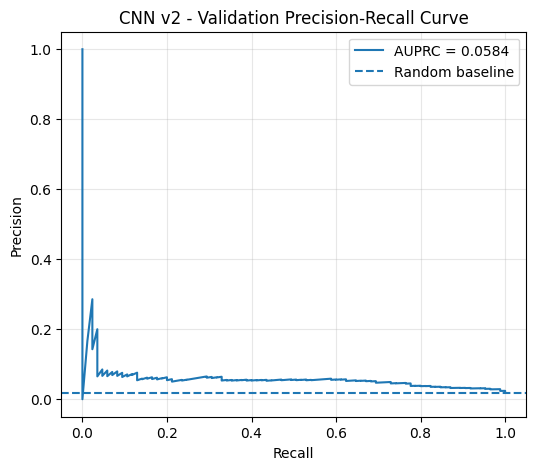

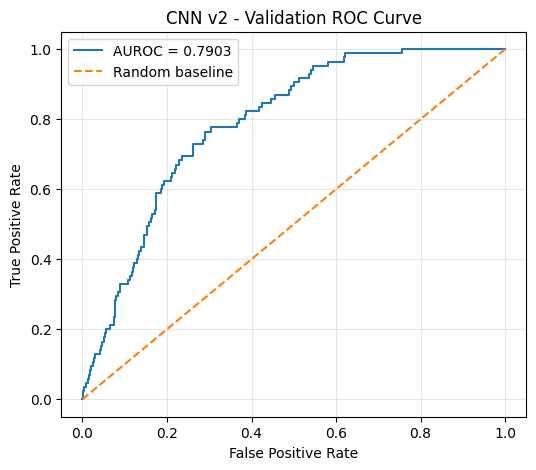

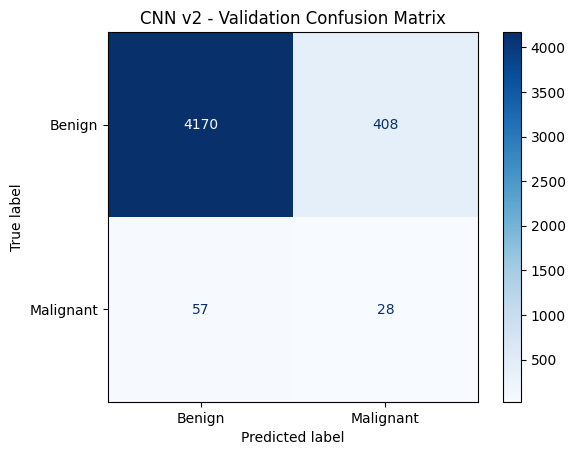

Saved CNN v2 results in Drive: /content/isic_lightweight_cnn_retrain/results/cnn_v2


In [26]:
import json
import shutil
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve

save_dir_v2 = RESULTS_DIR / "cnn_v2"
save_dir_v2.mkdir(exist_ok=True)

# Save metrics
with open(save_dir_v2 / "metrics.json", "w") as f:
    json.dump(metrics_v2, f, indent=4)

# Save validation predictions
predictions_v2 = val_meta[
    ["cache_index", "target"]
].reset_index(drop=True).copy()

predictions_v2["probability_malignant"] = probs_v2
predictions_v2["predicted_label"] = preds_v2

predictions_v2.to_csv(
    save_dir_v2 / "validation_predictions.csv",
    index=False
)

# Save training history
pd.DataFrame(history_v2).to_csv(
    save_dir_v2 / "training_history.csv",
    index=False
)

# Save model checkpoint
shutil.copy2(
    CNN2_CKPT,
    save_dir_v2 / "best_lightweight_cnn_v2.pth"
)

# Precision-recall curve
plt.figure(figsize=(6, 5))
plt.plot(recall, precision, label=f"AUPRC = {metrics_v2['AUPRC']:.4f}")
plt.axhline(labels_v2.mean(), linestyle="--", label="Random baseline")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("CNN v2 - Validation Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(save_dir_v2 / "pr_curve.png", dpi=300, bbox_inches="tight")
plt.show()

# ROC curve
fpr, tpr, _ = roc_curve(labels_v2, probs_v2)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUROC = {metrics_v2['AUROC']:.4f}")
plt.plot([0, 1], [0, 1], "--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("CNN v2 - Validation ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(save_dir_v2 / "roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

# Confusion matrix
cm = confusion_matrix(labels_v2, preds_v2, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("CNN v2 - Validation Confusion Matrix")
plt.savefig(
    save_dir_v2 / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Create ZIP
shutil.make_archive(
    str(RESULTS_DIR / "cnn_v2"),
    "zip",
    save_dir_v2
)

print("Saved CNN v2 results in Drive:", save_dir_v2)

## 4. Fresh validation comparison

The table below is computed from the **new run**. The previous notebook's numbers are historical and should not be copied into this run's results. The F1 thresholds are selected **only on validation data**. Accuracy may be misleading due to class imbalance; prioritize AUPRC and sensitivity.


In [35]:
import pandas as pd
comparison = pd.DataFrame({
    'metric': ['AUPRC','AUROC','Accuracy','Specificity','MCC','Precision','Recall','F1','Balanced Accuracy','Threshold','TP','FP','FN','TN','Trainable Parameters'],
    'cnn_v1': [metrics.get(k) for k in ['AUPRC','AUROC','Accuracy','Specificity','MCC','Precision','Recall','F1','Balanced Accuracy','Threshold','TP','FP','FN','TN']] + [sum(p.numel() for p in model.parameters())],
    'cnn_v2': [metrics_v2.get(k) for k in ['AUPRC','AUROC','Accuracy','Specificity','MCC','Precision','Recall','F1','Balanced Accuracy','Threshold','TP','FP','FN','TN']] + [sum(p.numel() for p in model_v2.parameters())],
})
comparison.to_csv(RESULTS_DIR / 'validation_summary.csv', index=False)
comparison.to_csv(GITHUB_DIR / 'validation_summary.csv', index=False)
print(comparison.to_string(index=False))


              metric       cnn_v1       cnn_v2
               AUPRC     0.052015     0.058423
               AUROC     0.749187     0.790255
            Accuracy     0.929230     0.900279
         Specificity     0.941896     0.910878
                 MCC     0.105178     0.110414
           Precision     0.073171     0.064220
              Recall     0.247059     0.329412
                  F1     0.112903     0.107486
   Balanced Accuracy     0.594477     0.620145
           Threshold     0.222643     0.199568
                  TP    21.000000    28.000000
                  FP   266.000000   408.000000
                  FN    64.000000    57.000000
                  TN  4312.000000  4170.000000
Trainable Parameters 19457.000000 93825.000000


## 5. Final internal test evaluation — run once after model selection

This uses the **labeled patient-level internal test split** (`split_patient == "test"`) and the **validation-selected thresholds** (`best_threshold`, `best_threshold_v2`). It does not select thresholds on test data. The test evaluation runs automatically after training and validation. Run it once after finalizing the models and thresholds; do not tune on test results.

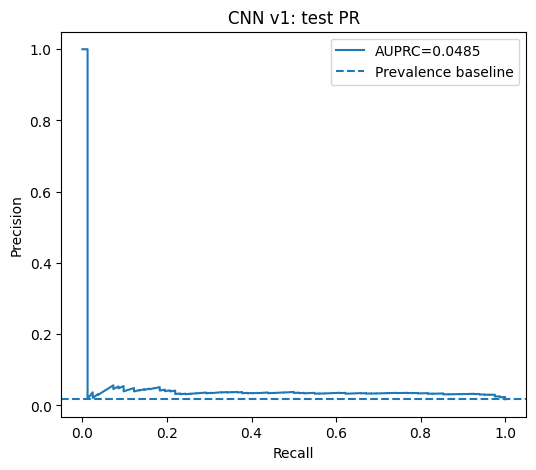

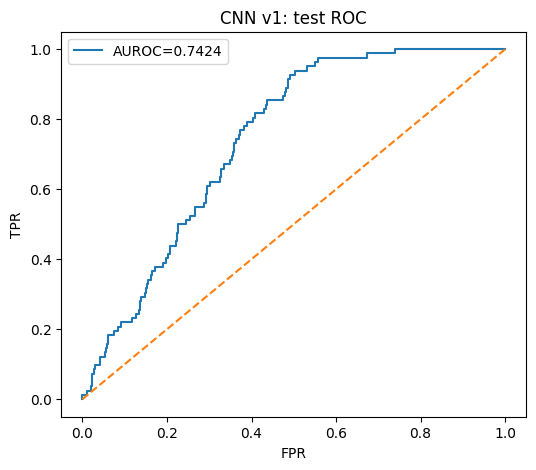

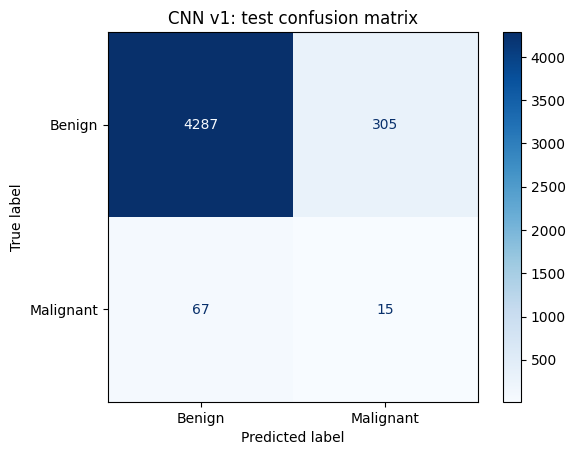

CNN v1 AUPRC                             0.0485
AUROC                             0.7424
Accuracy                          0.9204
Specificity                       0.9336
MCC                               0.0606
Precision                         0.0469
Recall                            0.1829
F1                                0.0746
Balanced Accuracy                 0.5583
Threshold (from validation)       0.2226
TP                               15.0000
FP                              305.0000
FN                               67.0000
TN                             4287.0000
Test samples                   4674.0000


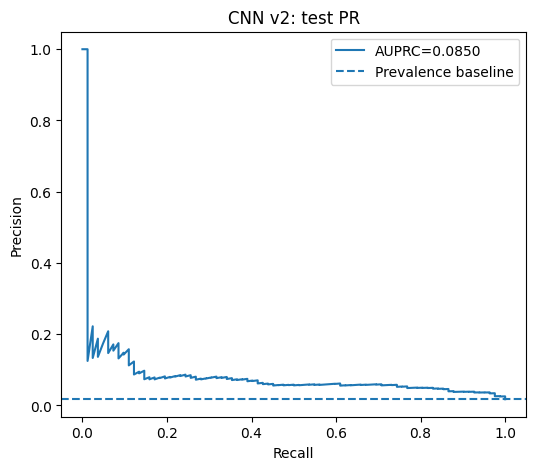

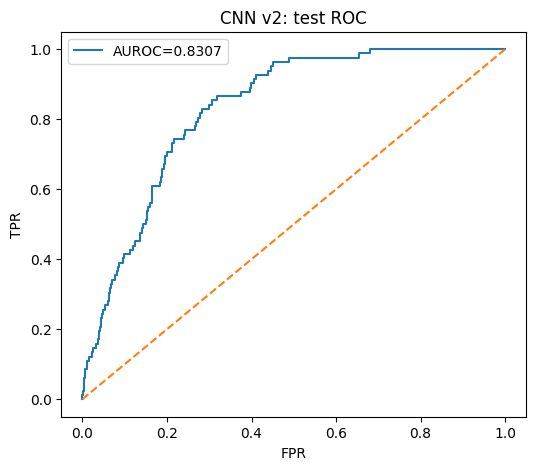

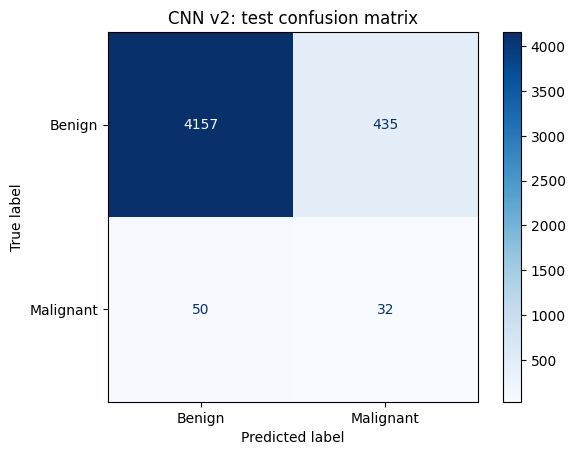

CNN v2 AUPRC                             0.0850
AUROC                             0.8307
Accuracy                          0.8962
Specificity                       0.9053
MCC                               0.1294
Precision                         0.0685
Recall                            0.3902
F1                                0.1166
Balanced Accuracy                 0.6478
Threshold (from validation)       0.1996
TP                               32.0000
FP                              435.0000
FN                               50.0000
TN                             4157.0000
Test samples                   4674.0000
                     metric      cnn_v1      cnn_v2
                      AUPRC    0.048455    0.084988
                      AUROC    0.742450    0.830660
                   Accuracy    0.920411    0.896234
                Specificity    0.933580    0.905270
                        MCC    0.060568    0.129372
                  Precision    0.046875    0.068522
              

In [36]:
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, f1_score, balanced_accuracy_score,
                             accuracy_score, matthews_corrcoef, confusion_matrix,
                             precision_recall_curve, roc_curve, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

def evaluate_heldout(net, loader, threshold, out_dir, model_name):
    out_dir.mkdir(parents=True, exist_ok=True)
    net.eval()
    scores, truths = [], []
    with torch.no_grad():
        for xb, yb in loader:
            logits = net(xb.to(device))
            scores.extend(torch.sigmoid(logits).cpu().numpy().reshape(-1))
            truths.extend(yb.cpu().numpy().reshape(-1))
    scores = np.asarray(scores)
    truths = np.asarray(truths).astype(int)
    preds = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(truths, preds, labels=[0, 1]).ravel()
    result = {
        'AUPRC': float(average_precision_score(truths, scores)),
        'AUROC': float(roc_auc_score(truths, scores)),
        'Accuracy': float(accuracy_score(truths, preds)),
        'Specificity': float(tn / (tn + fp)) if (tn + fp) else 0.0,
        'MCC': float(matthews_corrcoef(truths, preds)),
        'Precision': float(precision_score(truths, preds, zero_division=0)),
        'Recall': float(recall_score(truths, preds, zero_division=0)),
        'F1': float(f1_score(truths, preds, zero_division=0)),
        'Balanced Accuracy': float(balanced_accuracy_score(truths, preds)),
        'Threshold (from validation)': float(threshold),
        'TP': int(tp), 'FP': int(fp), 'FN': int(fn), 'TN': int(tn),
        'Test samples': int(len(truths))
    }
    (out_dir / 'metrics.json').write_text(json.dumps(result, indent=2))
    pd.DataFrame({'cache_index': test_meta['cache_index'].to_numpy(),
                  'target': truths, 'probability_malignant': scores,
                  'predicted_label': preds}).to_csv(out_dir / 'test_predictions.csv', index=False)
    p, r, _ = precision_recall_curve(truths, scores)
    plt.figure(figsize=(6, 5)); plt.plot(r, p, label=f"AUPRC={result['AUPRC']:.4f}")
    plt.axhline(truths.mean(), ls='--', label='Prevalence baseline')
    plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title(f'{model_name}: test PR')
    plt.legend(); plt.savefig(out_dir / 'test_pr_curve.png', dpi=180, bbox_inches='tight'); plt.show(); plt.close()
    fpr, tpr, _ = roc_curve(truths, scores)
    plt.figure(figsize=(6, 5)); plt.plot(fpr, tpr, label=f"AUROC={result['AUROC']:.4f}")
    plt.plot([0, 1], [0, 1], '--'); plt.xlabel('FPR'); plt.ylabel('TPR')
    plt.title(f'{model_name}: test ROC'); plt.legend()
    plt.savefig(out_dir / 'test_roc_curve.png', dpi=180, bbox_inches='tight'); plt.show(); plt.close()
    ConfusionMatrixDisplay.from_predictions(truths, preds, labels=[0,1],
        display_labels=['Benign','Malignant'], cmap='Blues', values_format='d')
    plt.title(f'{model_name}: test confusion matrix')
    plt.savefig(out_dir / 'test_confusion_matrix.png', dpi=180, bbox_inches='tight'); plt.show(); plt.close()
    print(model_name, pd.Series(result).round(4).to_string())
    return result

test_meta = meta[meta['split_patient'] == 'test'].copy()
if test_meta.empty or test_meta['target'].isna().any() or test_meta['target'].nunique() != 2:
    raise ValueError('The internal test split must exist and contain labeled benign and malignant cases.')
test_dataset = U.CachedISIC(CACHE_PATH, test_meta['cache_index'].to_numpy(),
                            test_meta['target'].to_numpy(), U.build_transforms(IMG_SIZE, train=False))
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=0, pin_memory=True)
model.load_state_dict(torch.load(CNN1_CKPT, map_location=device, weights_only=True))
model_v2.load_state_dict(torch.load(CNN2_CKPT, map_location=device, weights_only=True))
test_v1 = evaluate_heldout(model, test_loader, best_threshold,
                           RESULTS_DIR / 'cnn_v1' / 'test', 'CNN v1')
test_v2 = evaluate_heldout(model_v2, test_loader, best_threshold_v2,
                           RESULTS_DIR / 'cnn_v2' / 'test', 'CNN v2')
test_summary = pd.DataFrame({'metric': list(test_v1),
                             'cnn_v1': list(test_v1.values()),
                             'cnn_v2': [test_v2[k] for k in test_v1]})
test_summary.to_csv(RESULTS_DIR / 'test_summary.csv', index=False)
test_summary.to_csv(GITHUB_DIR / 'test_summary.csv', index=False)
print(test_summary.to_string(index=False))


## 6. Prepare GitHub-ready results

Exports CSV summaries and PNG plots to temporary Colab storage and automatically downloads a ZIP. Model checkpoints are **not** included in the ZIP: verify the separately downloaded `.pth` files on your computer. The shared preprocessing utility must be credited separately.


In [37]:
import shutil
from pathlib import Path

for name in ('cnn_v1', 'cnn_v2'):
    src_dir = RESULTS_DIR / name
    dest = GITHUB_DIR / 'results' / name
    dest.mkdir(parents=True, exist_ok=True)
    for f in src_dir.glob('*'):
        if f.is_file() and f.suffix.lower() in ('.csv', '.json', '.png'):
            shutil.copy2(f, dest / f.name)
    td = dest / 'test'; td.mkdir(exist_ok=True)
    for f in (src_dir / 'test').glob('*'):
        if f.is_file() and f.suffix.lower() in ('.csv', '.json', '.png'):
            shutil.copy2(f, td / f.name)

readme = f"""# Lightweight CNN v1 and v2 — ISIC 2020

Two convolutional networks trained **from scratch** using the team's shared
`isic_utils.py` preprocessing and patient-level splits.

- CNN v1: 19,457 trainable parameters (two convolutional blocks).
- CNN v2: 93,825 trainable parameters (three blocks with BatchNorm).
- Class-weighted BCEWithLogitsLoss, AdamW, warmup/cosine scheduling,
  early stopping/checkpoint selection on **validation AUPRC**.
- F1-maximizing decision thresholds selected **on validation only**.

## Results

See `validation_summary.csv` for **new-run validation results**.
See `test_summary.csv` for one-time held-out internal test results.

## Reproduction

Open `train_lightweight_cnn.ipynb` in Google Colab. Supply matching
`metadata.csv`, `images_uint8_new.npy`, and team `isic_utils.py`; edit the
input paths in the setup cell. Best `.pth` files are saved in temporary Colab storage at
`/content/checkpoints` and browser downloads are triggered on each improvement.
**Verify the final best checkpoints were downloaded to your computer.**

The 2020 competition test set is unlabeled; test results (if present) are
from the team's labeled internal patient-level holdout, not the competition test.

## Attribution

Shared preprocessing and dataset splitting are the team's work. The
CNN v1/v2 from-scratch architectures, training and evaluation are the
contribution of Muhammad Mubinur Rahman. AI assistance was used in code
preparation and debugging; results require actual execution.
"""
(GITHUB_DIR / 'README.md').write_text(readme)
(GITHUB_DIR / '.gitignore').write_text('*.npy\n*.pth\n*.pt\n*.zip\n__pycache__/\n.ipynb_checkpoints/\n')
print('GitHub-ready results:', GITHUB_DIR)
print('TEMPORARY Colab checkpoints:', CNN1_CKPT, CNN2_CKPT)
print('Checkpoints exist:', CNN1_CKPT.is_file(), CNN2_CKPT.is_file())

# Download final GitHub-ready results bundle (does not contain model weights).
archive_path = shutil.make_archive('/content/isic_cnn_github_results', 'zip', root_dir=str(GITHUB_DIR))
try:
    files.download(archive_path)
except Exception as exc:
    print('WARNING: results ZIP download failed:', exc)
print('VERIFY on your computer: both .pth checkpoints and isic_cnn_github_results.zip')


GitHub-ready results: /content/isic_lightweight_cnn_retrain/github_upload
TEMPORARY Colab checkpoints: /content/checkpoints/best_lightweight_cnn.pth /content/checkpoints/best_lightweight_cnn_v2.pth
Checkpoints exist: True True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

VERIFY on your computer: both .pth checkpoints and isic_cnn_github_results.zip
